# Creation of 2D histogram Plot for PE-relevant properties 
- to compare to Kukulies 2026 Fig 2
- input: final dataframes (monthly)
- output: 2D histogram of mean IPW against mean rain rate

# load packages 

In [1]:
import numpy as np
import xarray as xr
import os
import pandas as pd

from pathlib import Path

import sys

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Patch
import string


# load data

In [2]:
inputdir = "../output/final_dataframes/"
models = ["ICON","OBS"]
timeperiods = ["JUNE","DECEMBER"]

In [3]:
## load tracks
ds = {}
for model in models: 
    ds[model] = {}
    for timeperiod in timeperiods: 
        file = os.path.join(inputdir,f"anvil_features_{model}_{timeperiod}.h5")
        Tracks = pd.read_hdf(file, key='table') 
        
        Tracks = Tracks.rename(columns={
            "min_tb": "min_tb_anvil",
            "mean_iwp": "mean_iwp_anvil",
            "max_iwp": "max_iwp_anvil",
            "total_iwp":"total_iwp_anvil",
        })
        ds[model][timeperiod] = Tracks.reset_index()

In [4]:
ds["ICON"]["JUNE"].columns

Index(['index', 'time', 'feature_anvil', 'mean_iwp_anvil', 'total_iwp_anvil',
       'max_iwp_anvil', 'min_tb_anvil', 'area_anvil', 'd_eq_anvil',
       'mean_precip_anvil', 'total_precip_anvil', 'rain_volume_anvil',
       'n_children_anvil', 'iwp_volume_anvil', 'min_dist_anvil_km',
       'convective_rain_volume_anvil',
       'fraction_convection_rain_volume_anvil'],
      dtype='object')

## mean precip (not directly used in the PE calc tho) 

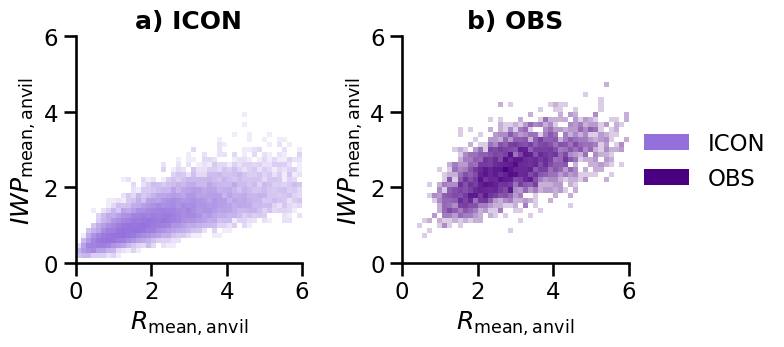

In [13]:
# sys.path.append("../tools")
# import defs_application

color_pe_icon ="mediumpurple"# defs_application.color_pe_icon
color_pe_obs ="indigo" # defs_application.color_pe_obs

tmpmodels = ["ICON","OBS"]
colors = [color_pe_icon,color_pe_obs]

sns.set_context("talk")
fig, ax = plt.subplots(1, 2, figsize=(8, 5))

for i, (axis, model, color) in enumerate(zip(ax, tmpmodels, colors)):

    x = ds[model]["JUNE"]["mean_precip_anvil"]
    y = ds[model]["JUNE"]["mean_iwp_anvil"]

    cmap = LinearSegmentedColormap.from_list(
        f"{model}_cmap",
        ["white", color]
    )

    axis.hist2d(
        x,
        y,
        bins=45,
        range=[[0, 6], [0, 6]],
        norm=LogNorm(),
        cmap=cmap,
    )

    axis.set_xlim(0, 6)
    axis.set_ylim(0, 6)
    axis.set_aspect("equal", adjustable="box")

    panel_label = string.ascii_lowercase[i]
    axis.set_title(f"{panel_label}) {model}", fontweight="bold")

    axis.set_xlabel(r'$R_{\mathrm{mean,anvil}}$')#r" (mm h$^{-1}$)")
    axis.set_ylabel(r'$IWP_{\mathrm{mean,anvil}}$')#r"mean IWP (kg m$^{-2}$)")
# Legend
legend_handles = [
    Patch(facecolor=color_pe_icon, label="ICON"),
    Patch(facecolor=color_pe_obs, label="OBS"),
]

fig.legend(
    handles=legend_handles,
    loc="center left",
    ncol=1,
    frameon=False,
    bbox_to_anchor=(0.8, 0.5),
)

sns.despine()
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.savefig("../output/plots/PE_scatter_plots_example.pdf",bbox_inches="tight",
            pad_inches=0.02)
plt.show()